In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv('fraudetection.csv')

In [3]:
print(df.shape)
print()
print(df.dtypes)
print()
print(df.head(3))
print()
# checking for nulls
print(df.isnull().sum())

(6362620, 11)

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

   step      type   amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT  9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT  1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER   181.00  C1305486145          181.0            0.00   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  

step              0
type              0
amount            0
nameOrig          0
oldbalance

In [4]:
df['balance_drained'] = (df['newbalanceOrig'] == 0) & (df['oldbalanceOrg'] > 0)
df['dest_no_change'] = (df['newbalanceDest'] - df['oldbalanceDest']) == 0  
df['is_high_risk_type'] = df['type'].isin(['TRANSFER', 'CASH_OUT'])

df['eda_fraud_flag'] = (
    df['is_high_risk_type'] &
    df['dest_no_change'] &        # ← used here (was dest_no_chnage)
    (df['amount'] > 100_000)
)

precision = df[df['eda_fraud_flag']]['isFraud'].mean()
recall = df[df['isFraud'] == 1]['eda_fraud_flag'].mean()
print(f'Rule Precision: {precision:.1%}, Recall: {recall:.1%}')  

Rule Precision: 79.1%, Recall: 39.4%


### 1. Class Imbalance

Before building any rules, we need to understand exactly how rare fraud is in this dataset. This is the foundation of the Veracity argument.

In [5]:
# raw counts and perecnetage breakdown
fraud_counts = df['isFraud'].value_counts()
fraud_perct=df['isFraud'].value_counts(normalize=True).mul(100).round(3)

print('Counts:')
print(fraud_counts)
print()
print('Percentage')
print(fraud_perct)
print()
print(f'Imnbalance ratio(legit:fraud) = {fraud_counts[0]/fraud_counts[1]:.0f}:1')

Counts:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Percentage
isFraud
0    99.871
1     0.129
Name: proportion, dtype: float64

Imnbalance ratio(legit:fraud) = 774:1


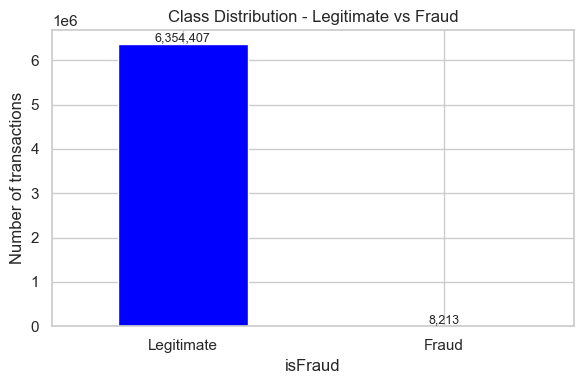

In [6]:
# Visualise the imbalance
fig, ax = plt.subplots(figsize=(6,4))
fraud_counts.plot(kind='bar', color=['blue','crimson'],ax=ax)
ax.set_title('Class Distribution - Legitimate vs Fraud')
ax.set_xticklabels(['Legitimate','Fraud'],rotation = 0)
ax.set_ylabel('Number of transactions')
for i, v in enumerate(fraud_counts):
    ax.text(i,v,f'{v:,}', ha='center', va = 'bottom', fontsize=9)
plt.tight_layout()
plt.savefig('class_imbalance.png',dpi=150)
plt.show()

In [7]:
df.groupby('type')['isFraud'].agg(['sum','count','mean']).round(5)

,sum,count,mean
type,,,
CASH_IN,0,1399284,0.00000
CASH_OUT,4116,2237500,0.00184
DEBIT,0,41432,0.00000
PAYMENT,0,2151495,0.00000
TRANSFER,4097,532909,0.00769


EDA revealed that fraudulent activity is exclusively concentrated in TRANSFER and CASH_OUT transaction types — 100% of all 8,213 fraud cases fall into these two categories. The remaining three types (PAYMENT, DEBIT, CASH_IN) contain zero fraud cases across 3.59 million transactions. Within the high-risk types, TRANSFER carries a fraud rate of 0.769% compared to 0.184% for CASH_OUT, making TRANSFER transactions the higher-priority target for real-time detection. This finding directly informs our Spark rule engine: all incoming transactions are first filtered by type, eliminating 56% of the stream from further processing before any other check runs.

### Balancing the imbalance

In [8]:
# Feature atures- using EDA derived columns
features = ['amount','oldbalanceOrg', 'newbalanceOrig','oldbalanceDest','newbalanceDest','is_high_risk_type','balance_drained','dest_no_change']
X = df[features]
y = df['isFraud']

In [9]:
# Startified split - preserves 0.13% fraud rate in both halves
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, stratify=y,random_state=42)

Legit amounts:
count     6354407.00
mean       178197.04
std        596236.98
min             0.01
25%         13368.40
50%         74684.72
75%        208364.76
max      92445516.64
Name: amount, dtype: float64

Fraud amounts:
count        8213.00
mean      1467967.30
std       2404252.95
min             0.00
25%        127091.33
50%        441423.44
75%       1517771.48
max      10000000.00
Name: amount, dtype: float64


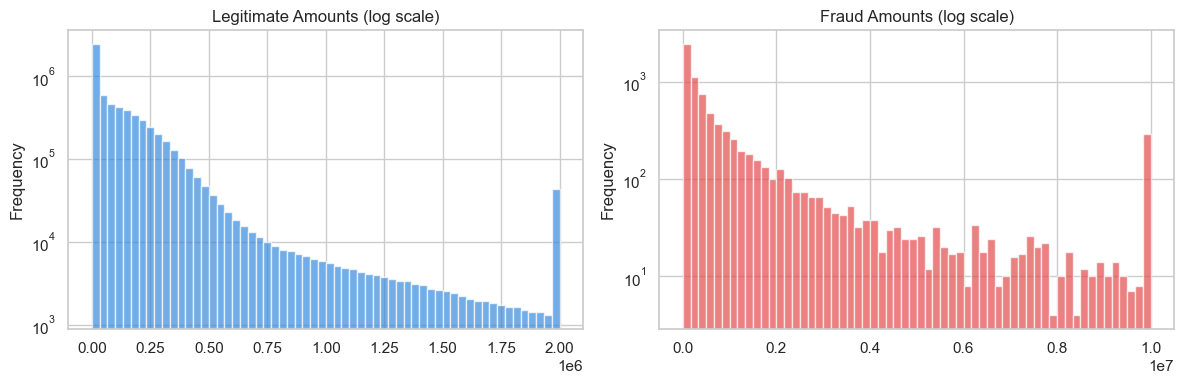

In [10]:
# amount distribution
print("Legit amounts:"); print(df[df['isFraud']==0]['amount'].describe().round(2))
print("\nFraud amounts:"); print(df[df['isFraud']==1]['amount'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[df['isFraud']==0]['amount'].clip(upper=2e6).plot(
    kind='hist', bins=60, ax=axes[0], color='#378ADD', alpha=0.7, logy=True)
axes[0].set_title('Legitimate Amounts (log scale)')
df[df['isFraud']==1]['amount'].plot(
    kind='hist', bins=60, ax=axes[1], color='#E24B4A', alpha=0.7, logy=True)
axes[1].set_title('Fraud Amounts (log scale)')
plt.tight_layout()
plt.savefig('amount_distribution.png', dpi=150)
plt.show()

In [11]:
# balance anomaly diagnoses
print(f"balance_drained rate — fraud: {df[df['isFraud']==1]['balance_drained'].mean():.1%}")
print(f"balance_drained rate — legit: {df[df['isFraud']==0]['balance_drained'].mean():.1%}")
print()
print(f"dest_no_change rate  — fraud: {df[df['isFraud']==1]['dest_no_change'].mean():.1%}")
print(f"dest_no_change rate  — legit: {df[df['isFraud']==0]['dest_no_change'].mean():.1%}")

balance_drained rate — fraud: 97.6%
balance_drained rate — legit: 23.8%

dest_no_change rate  — fraud: 49.8%
dest_no_change rate  — legit: 36.4%


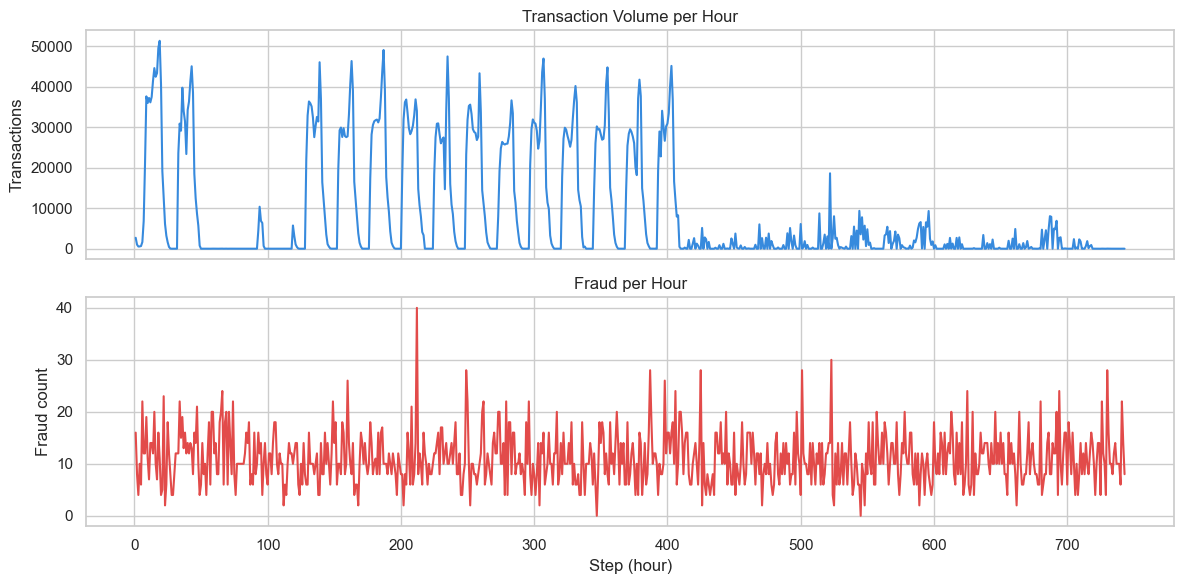

In [12]:
# time - step analysis
volume_by_step = df.groupby('step').size()
fraud_by_step  = df.groupby('step')['isFraud'].sum()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
volume_by_step.plot(ax=ax1, color='#378ADD')
ax1.set_title('Transaction Volume per Hour'); ax1.set_ylabel('Transactions')
fraud_by_step.plot(ax=ax2, color='#E24B4A')
ax2.set_title('Fraud per Hour'); ax2.set_ylabel('Fraud count'); ax2.set_xlabel('Step (hour)')
plt.tight_layout()
plt.savefig('time_step_analysis.png', dpi=150)
plt.show()

In [13]:
# Train with balanced class weights
model = RandomForestClassifier(
    n_estimators = 100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1     # speeds up training
)
model.fit(X_train, y_train)
# Evaluate with the right metrics
y_pred = model.predict(X_test)
print(classification_report(y_test,y_pred,target_names=['Legitimate','Fraud']))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00   1270881
       Fraud       0.96      0.78      0.86      1643

    accuracy                           1.00   1272524
   macro avg       0.98      0.89      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524



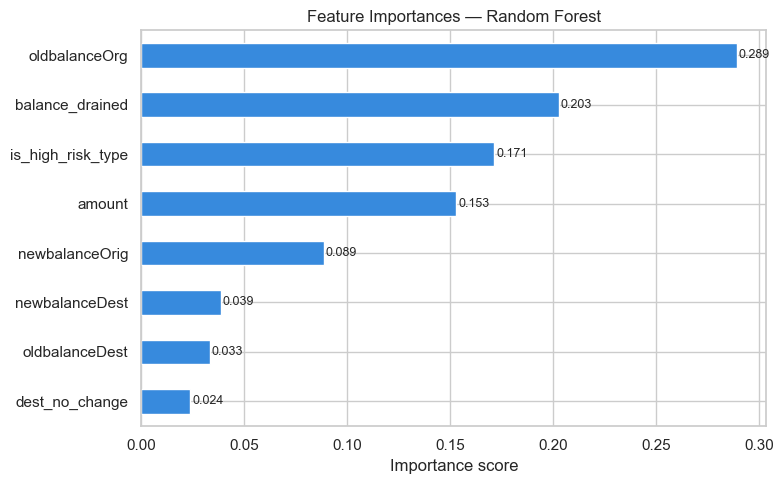

In [14]:
# feature importances
rf_features = ['amount', 'oldbalanceOrg', 'newbalanceOrig',
               'oldbalanceDest', 'newbalanceDest',
               'is_high_risk_type', 'balance_drained', 'dest_no_change']

importances = pd.Series(
    model.feature_importances_, 
    index=rf_features
).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', color='#378ADD', ax=ax)
ax.set_title('Feature Importances — Random Forest')
ax.set_xlabel('Importance score')
for i, v in enumerate(importances):
    ax.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('feature_importances.png', dpi=150)
plt.show()

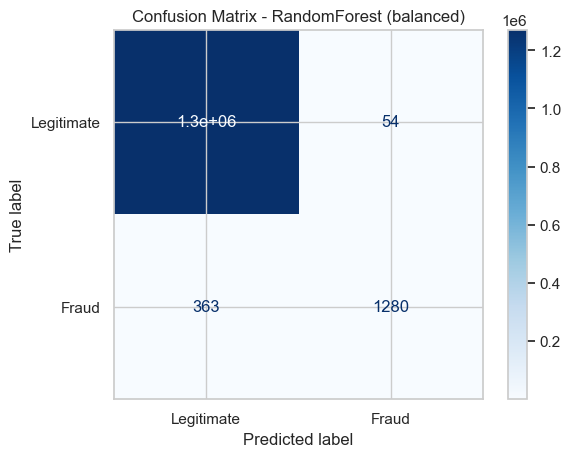

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_test,y_pred)
disp=ConfusionMatrixDisplay(cm,display_labels=['Legitimate','Fraud'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - RandomForest (balanced)')
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

In [16]:
import joblib
joblib.dump(model, 'fraud_rf.joblib')
print("Model saved — fraud_rf.joblib")

Model saved — fraud_rf.joblib


### Isolation Forest

In [17]:
from sklearn.ensemble import IsolationForest

# Use the same features as your Random Forest
features = ['amount', 'oldbalanceOrg', 'newbalanceOrig',
            'oldbalanceDest', 'newbalanceDest']

# Train on a sample — Isolation Forest on 6M rows is slow
# Use high-risk transactions only (TRANSFER + CASH_OUT)
sample = df[df['is_high_risk_type']].sample(n=100_000, random_state=42)

iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.002,   # ← tells the model ~0.2% of data is anomalous
    random_state=42,
    n_jobs=-1
)
iso_model.fit(sample[features])

# Score — -1 means anomaly, 1 means normal
sample['iso_flag'] = iso_model.predict(sample[features])
sample['iso_score'] = iso_model.score_samples(sample[features])

# How well does it overlap with actual fraud?
flagged = sample[sample['iso_flag'] == -1]
print(f"Flagged as anomaly: {len(flagged):,}")
print(f"Of those, actual fraud: {flagged['isFraud'].mean():.2%}")
print(f"Recall on sample: {(flagged['isFraud'].sum() / sample['isFraud'].sum()):.2%}")

Flagged as anomaly: 200
Of those, actual fraud: 8.50%
Recall on sample: 5.94%


Our current system uses a supervised Random Forest classifier which requires labelled fraud examples. A future extension would incorporate Isolation Forest as an unsupervised anomaly detector, which could identify novel fraud patterns that have never been seen in training data — a critical capability since fraud tactics evolve continuously.

In [18]:
from sklearn.ensemble import IsolationForest
import joblib

# Train only on high-risk transaction types
high_risk = df[df['is_high_risk_type']][
    ['amount', 'oldbalanceOrg', 'newbalanceOrig',
     'oldbalanceDest', 'newbalanceDest']
]

iso = IsolationForest(
    n_estimators=100,
    contamination=0.002,   # ~0.2% expected anomaly rate
    random_state=42,
    n_jobs=-1
)
iso.fit(high_risk)

joblib.dump(iso, 'isolation_forest.joblib')
print("Isolation Forest saved")

Isolation Forest saved


In [19]:
from sklearn.ensemble import IsolationForest
import joblib

iso_features = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

sample = df[df['is_high_risk_type'] == True].sample(n=50000, random_state=42)

iso_model = IsolationForest(n_estimators=100, contamination=0.002, random_state=42, n_jobs=-1)
iso_model.fit(sample[iso_features])

joblib.dump(iso_model, 'isolation_forest.joblib')
print("Isolation Forest saved!")

Isolation Forest saved!
